In [11]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


In [12]:

data = {
    "Artist": [
        "Morgan Wallen",
        "Bruno Mars",
        "Ella Langley",
        "Olivia Rodrigo",
        "Luke Combs",
        "Taylor Swift",
        "JENNIE",
        "Malcolm Todd",
        "sombr",
        "Lainey Wilson",
        "Stella Lefty"
    ],

    "Plant": [
        "No", "No", "No", "No", "No",
        "Yes", "Yes", "Yes", "Yes", "Yes", "Yes"
    ],

    "Radio_Spins": [
        13668,
        11556,
        21527,
        14450,
        18672,
        15523,
        17981,
        11087,
        12311,
        15330,
        27726
    ]
}

df = pd.DataFrame(data)

df


,Artist,Plant,Radio_Spins
0,Morgan Wallen,No,13668
1,Bruno Mars,No,11556
2,Ella Langley,No,21527
3,Olivia Rodrigo,No,14450
4,Luke Combs,No,18672
5,Taylor Swift,Yes,15523
6,JENNIE,Yes,17981
7,Malcolm Todd,Yes,11087
8,sombr,Yes,12311
9,Lainey Wilson,Yes,15330


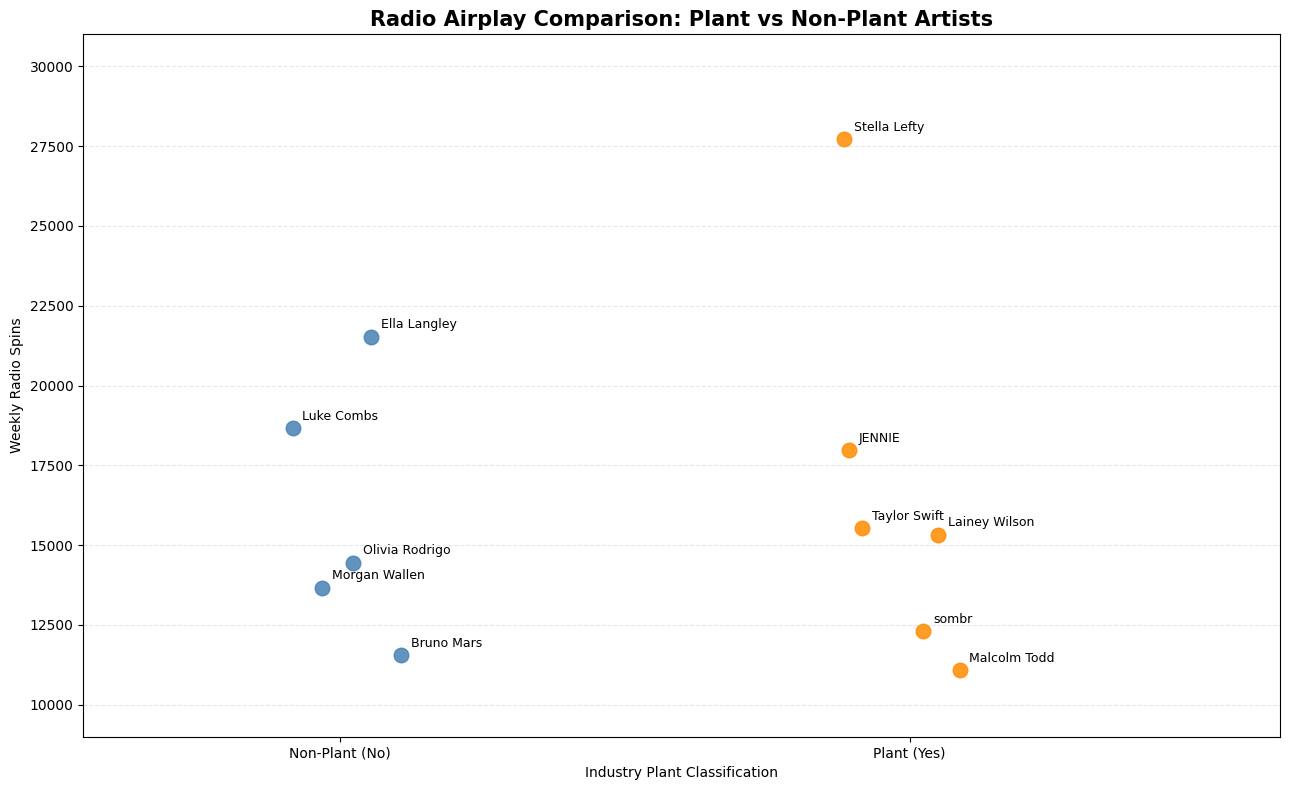

In [15]:
import numpy as np
plt.figure(figsize=(13, 8))

# Set positions for the two groups
np.random.seed(42)
x_positions = df["Plant"].map({"No": 0, "Yes": 1})
jitter = np.random.uniform(-0.12, 0.12, len(df))

colors = {"No": "steelblue", "Yes": "darkorange"}

# Plot each artist and label the dot
for i, row in df.iterrows():
    x = x_positions.loc[i] + jitter[i]
    y = row["Radio_Spins"]

    plt.scatter(
        x, y,
        color=colors[row["Plant"]],
        s=110,
        alpha=0.85
    )

    plt.annotate(
        row["Artist"],
        (x, y),
        xytext=(7, 6),
        textcoords="offset points",
        fontsize=9
    )

# Customize the chart
plt.xticks([0, 1], ["Non-Plant (No)", "Plant (Yes)"])
plt.xlim(-0.45, 1.65)
plt.ylim(9000, 31000)

plt.title(
    "Radio Airplay Comparison: Plant vs Non-Plant Artists",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Industry Plant Classification")
plt.ylabel("Weekly Radio Spins")

plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.tight_layout()

# Save the labeled plot
plt.savefig(
    "radio_airplay_labeled.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [8]:

# Calculate average radio spins for each group
averages = df.groupby("Plant")["Radio_Spins"].mean()

print("Average Weekly Radio Spins:")
print(averages.round(2))


Average Weekly Radio Spins:
Plant
No     15974.60
Yes    16659.67
Name: Radio_Spins, dtype: float64


In [ ]:

summary = df.groupby("Plant")["Radio_Spins"].agg(
    ["count", "mean", "median", "min", "max"]
)

print(summary.round(2))


       count      mean   median    min    max
Plant                                        
No         5  15974.60  14450.0  11556  21527
Yes        6  16659.67  15426.5  11087  27726


In [ ]:

from google.colab import files

files.download("radio_airplay_scatter.png")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>